# 03 · Similarity and semantic search evaluation

Ground truth for similarity: two documents are relevant to each other if they share a primary
CPC subgroup (patents) or one cites the other. Metrics are averaged over every document that
has at least one relevant document. Produced by `python -m src.pipeline.similarity`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import load_config
from src.pipeline.similarity import SimilarityIndex, choose_threshold, neighbour_pairs

sns.set_theme(style="whitegrid")
FIG = Path("reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
cfg = load_config()
sim = json.loads(Path("reports/similarity_eval.json").read_text())
search = json.loads(Path("reports/search_eval.json").read_text())
docs = pd.read_parquet("data/processed/documents.parquet")
vec = np.load("data/processed/embeddings_minilm.npy")

## Retrieval quality by embedding
MiniLM ranks relevant documents highest (MRR and Recall@10), ahead of SPECTER2 and a TF-IDF + SVD
baseline; random vectors give a floor of about zero. Precision@10 is small in absolute terms
because most documents have only one or two relevant documents in the corpus, so even a
perfect ranking cannot fill ten slots.

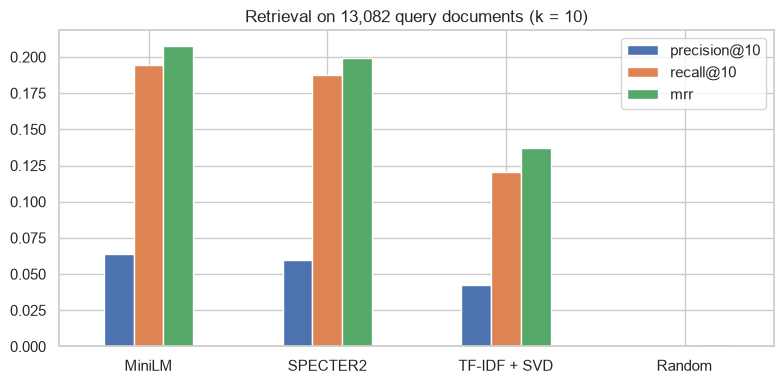

,precision@10,recall@10,mrr
MiniLM,0.0639,0.1942,0.2079
SPECTER2,0.0595,0.1874,0.1993
TF-IDF + SVD,0.0422,0.1205,0.1369
Random,0.0004,0.0005,0.0014


In [2]:
names = {"minilm": "MiniLM", "specter2": "SPECTER2", "tfidf_svd_baseline": "TF-IDF + SVD", "random_baseline": "Random"}
table = pd.DataFrame({names[k]: sim[k] for k in names}).T[["precision@10", "recall@10", "mrr"]]
ax = table.plot.bar(figsize=(8, 4), rot=0)
ax.set_title(f"Retrieval on {sim['minilm']['queries']:,} query documents (k = 10)")
plt.tight_layout(); plt.savefig(FIG / "similarity_retrieval.png", dpi=150); plt.show()
table

## Choosing the cross-institution similarity threshold
For every document we take its 10 nearest neighbours from *other* institutions. The threshold
is the lowest cosine similarity at which at least 95% of those pairs share a domain.

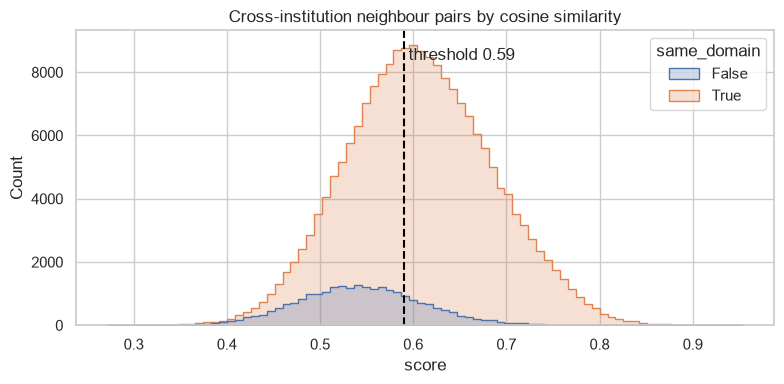

,mean,size
score,,
"(0.3, 0.35]",0.628,94
"(0.35, 0.4]",0.630,698
"(0.4, 0.45]",0.669,4618
"(0.45, 0.5]",0.740,17444
"(0.5, 0.55]",0.818,38140
"(0.55, 0.6]",0.885,54698
"(0.6, 0.65]",0.934,51191
"(0.65, 0.7]",0.969,34123
"(0.7, 0.75]",0.984,17448


In [3]:
index = SimilarityIndex(docs, vec, cfg["models"]["embedding"])
pairs = neighbour_pairs(index)
threshold = choose_threshold(pairs)
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=pairs, x="score", hue="same_domain", bins=80, element="step", ax=ax)
ax.axvline(threshold, color="black", ls="--"); ax.text(threshold + 0.005, ax.get_ylim()[1] * 0.9, f"threshold {threshold}")
ax.set_title("Cross-institution neighbour pairs by cosine similarity")
plt.tight_layout(); plt.savefig(FIG / "similarity_threshold.png", dpi=150); plt.show()
bins = pd.cut(pairs["score"], np.arange(0.3, 1.01, 0.05))
pairs.groupby(bins, observed=True)["same_domain"].agg(["mean", "size"]).round(3)

## Example: similar innovations from other institutions

In [4]:
example = docs[(docs["source"] == "patent") & (docs["domain"] == "Healthcare")].iloc[0]
print(example["title"], "—", example["institution_name"])
index.similar(example["doc_id"], 5)[["title", "institution_name", "source", "domain", "score", "other_institution"]]

Phase measurement, analysis, and correction methods for coherent imaging systems — University Illinois


,title,institution_name,source,domain,score,other_institution
0,Systems and methods for bulk motion compensati...,Oregon Health & Science University,patent,Healthcare,0.6156,True
1,Wavefront shaping with coherent optical sensing,Johns Hopkins University,patent,Healthcare,0.5825,True
2,Method and apparatus for motion correction in ...,The University of Sydney,patent,Healthcare,0.5704,True
3,Single shot analyzer grating for differential ...,Stanford University,patent,Healthcare,0.5624,True
4,Arrangement and method for robust single-shot ...,University of Stuttgart,patent,Healthcare,0.5613,True


## Semantic search: 20 hand-written queries
Precision@10 counts a result as correct when its domain matches the query's intended domain.

In [5]:
print("Overall Precision@10:", search["precision@10"])
pd.DataFrame(search["per_query"])[["domain", "query", "precision@10"]]

Overall Precision@10: 0.97


,domain,query,precision@10
0,Artificial Intelligence,neural network training method with reduced me...,1.0
1,Artificial Intelligence,large language model for question answering,1.0
2,Artificial Intelligence,reinforcement learning agent for decision making,0.8
3,Artificial Intelligence,graph neural network for node classification,1.0
4,Healthcare,wearable sensor for continuous heart rate moni...,1.0
5,Healthcare,MRI image reconstruction for diagnosis,0.8
6,Healthcare,electronic health record system for patient data,0.9
7,Healthcare,minimally invasive surgical instrument,0.9
8,Robotics,robot arm grasping objects with a gripper,1.0
9,Robotics,path planning for autonomous mobile robots,1.0


In [6]:
index.search("deep learning for retinal disease detection", 5, domain="Healthcare")[["title", "institution_name", "year", "score"]]

W1102 11:44:08.385000 7604 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,title,institution_name,year,score
0,Classifying neurological disease status using ...,Columbia University,2025,0.5668
1,Artificial intelligence cataract analysis system,Zhongshan Ophthalmic Center Of Sun Yat Sen Uni...,2021,0.5620
2,Tear film break-up time measurement for screen...,University Yuan Ze,2020,0.4895
3,Vision test for determining retinal disease pr...,University of Pennsylvania,2021,0.4638
4,Deep Learning with an Attention Mechanism for ...,National Taipei University of Nursing and Heal...,2025,0.4628
